<a href="https://colab.research.google.com/github/bautylazza/TP1-CDD/blob/main/TP_1_CD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico 1 - Ciencia de Datos
A continuación se presenta el desarrollo correspondiente a cada etapa.

El conjunto de datos es un estándar en **Mantenimiento Predictivo (Industria 4.0)**. Representa el monitoreo de máquinas herramientas en una línea de producción.

### Identificadores y Categorización
* **idx:** Es el identificador único de la fila (índice).
* **parent_device_id:** Es el ID del equipo o dispositivo físico.
* **product_type:** Define la variante o calidad del producto que se está procesando. Típicamente categorizado como **L** (Low/Baja), **M** (Medium/Media) y **H** (High/Alta).

### Variables Físicas del Proceso (Features)
* **air_temp [K]:** Temperatura ambiente medida en Kelvin. Es una variable externa que puede influir en la disipación de calor de la máquina.
* **process_temp [K]:** Temperatura generada durante el proceso de fabricación, también en Kelvin.
* **speed [RPM]:** Velocidad de rotación de la herramienta en revoluciones por minuto. Es la potencia de giro aplicada.
* **torque [Nm]:** El par motor o fuerza de torsión medida en Newton-metros. Existe una relación física inversa con la velocidad: a mayor torque, suele haber menor velocidad, y viceversa.
* **tool_wear [min]:** El desgaste acumulado de la herramienta en minutos. Cada vez que la máquina procesa un producto, el desgaste aumenta hasta que la herramienta falla o es reemplazada.

### Variable Objetivo (Target)
* **target:** Es la etiqueta que indica el estado del equipo.
    * **Normal:** El equipo funciona correctamente.
    * **Failure:** Se ha detectado una falla (que puede deberse a sobrecalentamiento, rotura, fatiga, etc.). Nuestro objetivo será predecir esta columna.


## Parte 1 - Análisis exploratorio
Análisis exploratorio de los datos utilizando distintos tipos de funciones, gráficos y medidas estadísticas. Se tienen en cuenta los siguientes aspectos:
- Medidas de tendencia central.
- Medidas de dispersión.
- Distribuciones.
- Proporciones.
- Relaciones entre variables.

1) Realizar un análisis exploratorio de los datos utilizando distintos tipos de funciones, gráficos y medidas estadísticas. Tener en cuenta, entre otros aspectos:



In [ ]:
# Importar librerías
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import zscore
import seaborn as sns

In [ ]:
# Dimensiones
print("Dimensiones del DataFrame: ", df.ndim)

# Visualizar la forma del dataframe
print("Forma del DataFrame: ", df.shape)

# Tamaño
print("Tamaño del DataFrame: ", df.size)

Dimensiones del DataFrame:  2
Forma del DataFrame:  (14521, 9)
Tamaño del DataFrame:  130689


In [ ]:
# Determinación de cantidad de registros
cantidad = np.unique(df['parent_device_id']).size
print("Cantidad de máquinas distintas: ", cantidad)

Cantidad de máquinas distintas:  14521


In [ ]:
# Visualizar los primeros registros del dataframe
print("Primeros registros del DataFrame:")
df.head()

Primeros registros del DataFrame:


,idx,parent_device_id,product_type,air_temp [K],process_temp [K],speed [RPM],torque [Nm],tool_wear [min],target
0,0,5291,L,303.80,313.30,1406,52.10,166,normal
1,1,3908,L,302.30,311.20,1633,36.40,114,normal
2,2,10767,M,302.27,311.47,1228,68.75,187,failure
3,3,15484,L,302.35,311.93,1522,36.99,214,failure
4,4,784,L,296.70,307.90,1743,27.90,55,normal


In [ ]:
df = pd.read_csv("i40 (datos).csv")
# Descripción estadística
# Excluimos las columnas 'idx' y 'parent_device_id', ya que no son relevantes para la descripción estadística.
columnas_para_descripcion = df.columns.drop(['idx', 'parent_device_id'], errors='ignore')
print("\nDescripción estadística:")
print(df[columnas_para_descripcion].describe())


Descripción estadística:
       air_temp [K]  process_temp [K]   speed [RPM]   torque [Nm]  \
count  14481.000000      14521.000000  14521.000000  14521.000000   
mean     300.478975        310.165287   1513.389436     44.955809   
std        1.952737          1.329586    313.604170     14.226641   
min      295.300000        305.700000     -1.000000      3.800000   
25%      298.900000        309.200000   1354.000000     35.990000   
50%      300.600000        310.320000   1423.000000     46.700000   
75%      302.200000        311.090000   1561.000000     55.000000   
max      304.500000        313.800000   2886.000000     76.600000   

       tool_wear [min]  
count     14521.000000  
mean        124.921700  
std          70.105992  
min           0.000000  
25%          64.000000  
50%         127.000000  
75%         193.000000  
max         253.000000  


### Medidas de tendencia central
A continuación se desarrolla la obtención de las medidas de tendencia central.



In [ ]:
# Cálculo de media, media recortada, mediana y moda para las columnas estadísticas
# Excluimos las columnas 'idx' y 'parent_device_id' para el cálculo de estadísticas, ya que no son relevantes.
columnas_estadisticas = df.columns.drop(['idx', 'parent_device_id'], errors='ignore')

# Cálculo de la media para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("Media:\n", df[columnas_estadisticas].mean(numeric_only=True).to_string())

# Cálculo de la media recortada para las columnas estadísticas seleccionadas.
# La función trim_mean de scipy.stats se utiliza para calcular la media recortada, eliminando el 20% de los valores más bajos y el 20% de los valores más altos.
media_recortada = df[columnas_estadisticas].select_dtypes(include=np.number).apply(lambda x: stats.trim_mean(x.dropna(), 0.2))
print("\nMedia acotada al 20%:\n", media_recortada.to_string())

# Cálculo de la mediana para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("\nMediana:\n", df[columnas_estadisticas].median(numeric_only=True).to_string())

# Calcular la moda solo para columnas numéricas dentro de las columnas estadísticas seleccionadas
print("\nModa:\n", df[columnas_estadisticas].select_dtypes(include=np.number).mode().iloc[0].to_string())

Media:
 air_temp [K]         300.478975
process_temp [K]     310.165287
speed [RPM]         1513.389436
torque [Nm]           44.955809
tool_wear [min]      124.921700

Media acotada al 20%:
 air_temp [K]         300.587434
process_temp [K]     310.233171
speed [RPM]         1438.371629
torque [Nm]           46.063009
tool_wear [min]      128.791002

Mediana:
 air_temp [K]         300.60
process_temp [K]     310.32
speed [RPM]         1423.00
torque [Nm]           46.70
tool_wear [min]      127.00

Moda:
 air_temp [K]         300.7
process_temp [K]     310.6
speed [RPM]         1377.0
torque [Nm]           35.8
tool_wear [min]      208.0


### Medidas de dispersión
A continuación se desarrolla la obtención de las medidas de dispersión.


In [ ]:
# Cálculo de varianza, desviación estándar, desviación media absoluta, rango, cuartiles e IQR para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
# Cálculo de la varianza para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("Varianza:\n", df[columnas_estadisticas].var(numeric_only=True).to_string())

# Cálculo de la desviación estándar para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("\nDesviación Estándar:\n", df[columnas_estadisticas].std(numeric_only=True).to_string())

# Cálculo de la desviación media absoluta para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
mad_per_variable = df[columnas_estadisticas].select_dtypes(include=np.number).apply(lambda x: sm.robust.scale.mad(x.dropna())).to_string()
print("\nDesviación Media Absoluta por variable:\n", mad_per_variable)

# Cálculo del rango para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("\nRango:\n", (df[columnas_estadisticas].max(numeric_only=True) - df[columnas_estadisticas].min(numeric_only=True)).to_string())

# Cálculo de los cuartiles y el rango intercuartílico (IQR) para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
q1 = df[columnas_estadisticas].quantile(0.25, numeric_only=True)
q3 = df[columnas_estadisticas].quantile(0.75, numeric_only=True)
iqr = q3 - q1
print("\nPrimer Cuartil (Q1):\n", q1)
print("\nTercer Cuartil (Q3):\n", q3)
print("\nRango Intercuartílico (IQR):\n", iqr.to_string())

# Cálculo de los percentiles para las columnas estadísticas seleccionadas, asegurándonos de incluir solo columnas numéricas
print("\nPercentiles:\n", df[columnas_estadisticas].quantile([0.25, 0.5, 0.75], numeric_only=True).to_string())

Varianza:
 air_temp [K]            3.813184
process_temp [K]        1.767799
speed [RPM]         98347.575395
torque [Nm]           202.397312
tool_wear [min]      4914.850136

Desviación Estándar:
 air_temp [K]          1.952737
process_temp [K]      1.329586
speed [RPM]         313.604170
torque [Nm]          14.226641
tool_wear [min]      70.105992

Desviación Media Absoluta por variable:
 air_temp [K]          2.446294
process_temp [K]      1.349168
speed [RPM]         131.951597
torque [Nm]          14.084721
tool_wear [min]      96.369144

Rango:
 air_temp [K]           9.2
process_temp [K]       8.1
speed [RPM]         2887.0
torque [Nm]           72.8
tool_wear [min]      253.0

Primer Cuartil (Q1):
 air_temp [K]         298.90
process_temp [K]     309.20
speed [RPM]         1354.00
torque [Nm]           35.99
tool_wear [min]       64.00
Name: 0.25, dtype: float64

Tercer Cuartil (Q3):
 air_temp [K]         302.20
process_temp [K]     311.09
speed [RPM]         1561.00
torque [

### Distribuciones



A continuación desarrollamos el código para generar los **Histogramas**, que nos permite observar las distribuciones.

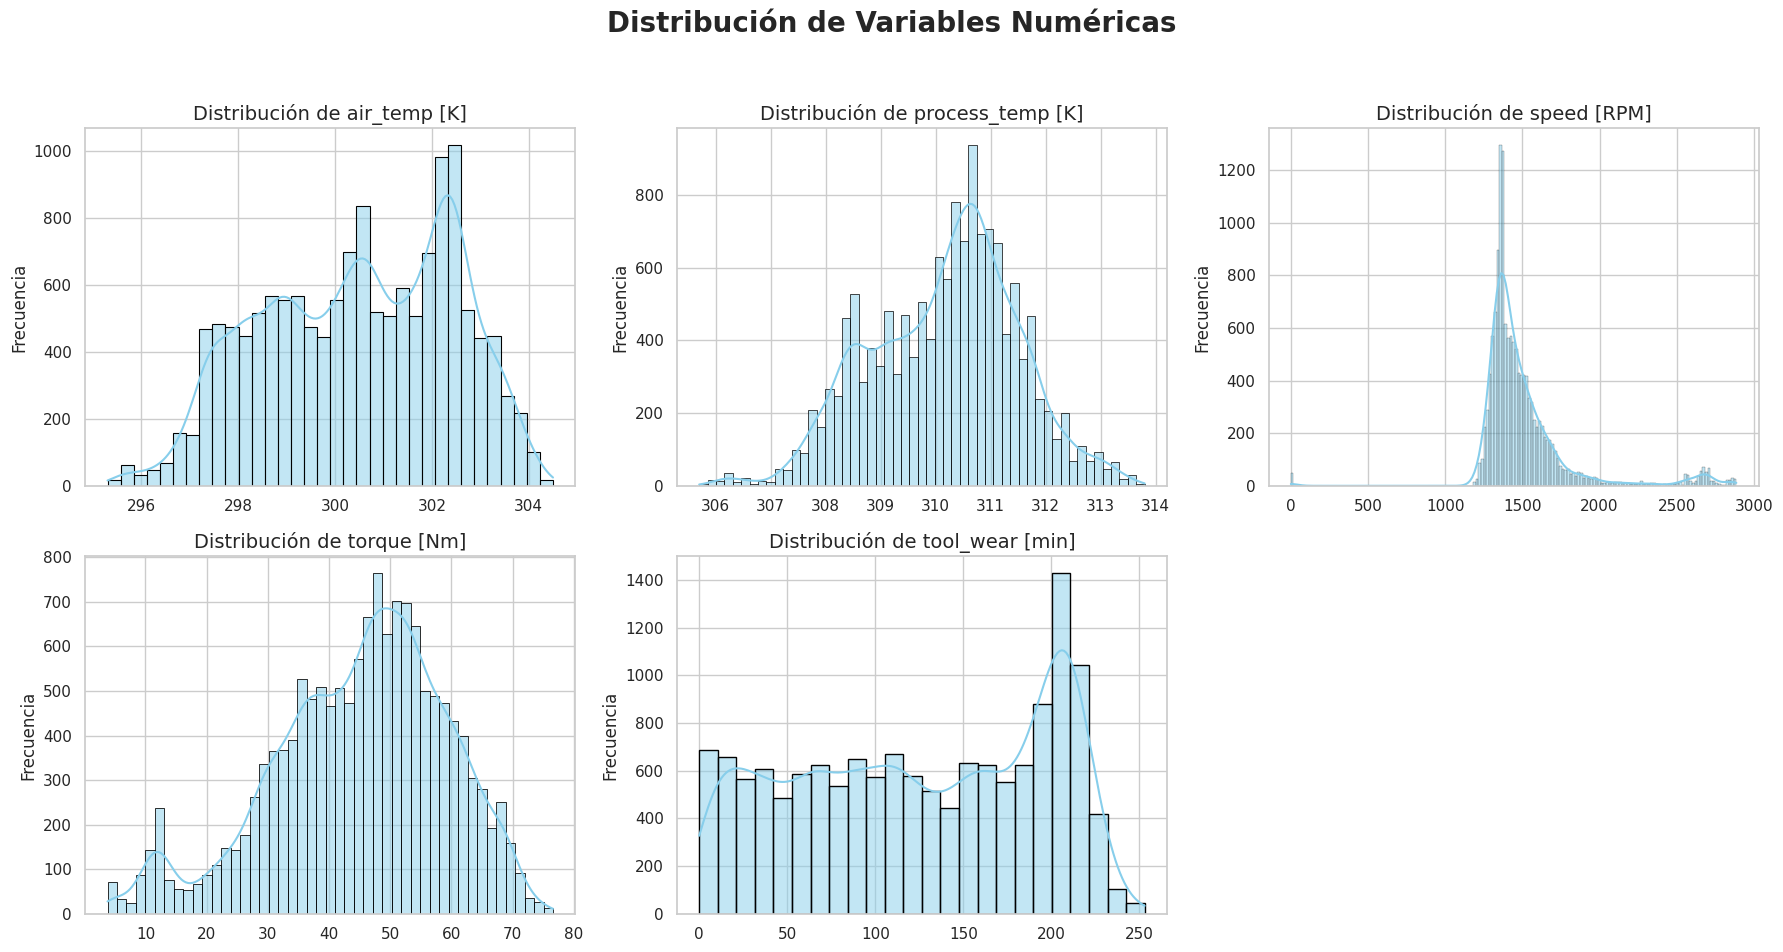

In [ ]:
# Configuración estética de Seaborn
sns.set_theme(style="whitegrid")

# Variables numéricas a analizar
cols_num = ['air_temp [K]', 'process_temp [K]', 'speed [RPM]', 'torque [Nm]', 'tool_wear [min]']

# Creación de la figura con subplots (grid de 2 filas x 3 columnas)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle('Distribución de Variables Numéricas', fontsize=20, fontweight='bold')

# Aplanamos el array de ejes para iterar fácilmente
axes = axes.flatten()

for i, col in enumerate(cols_num):
    sns.histplot(df[col], kde=True, ax=axes[i], color='skyblue', edgecolor='black')
    axes[i].set_title(f'Distribución de {col}', fontsize=14)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Frecuencia')

# Eliminamos el último subplot que queda vacío (si son 5 variables y 6 espacios)
if len(cols_num) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

A continuación desarrollamos el código para generar los Boxplot, que son fundamentales para identificar valores atípicos (outliers).

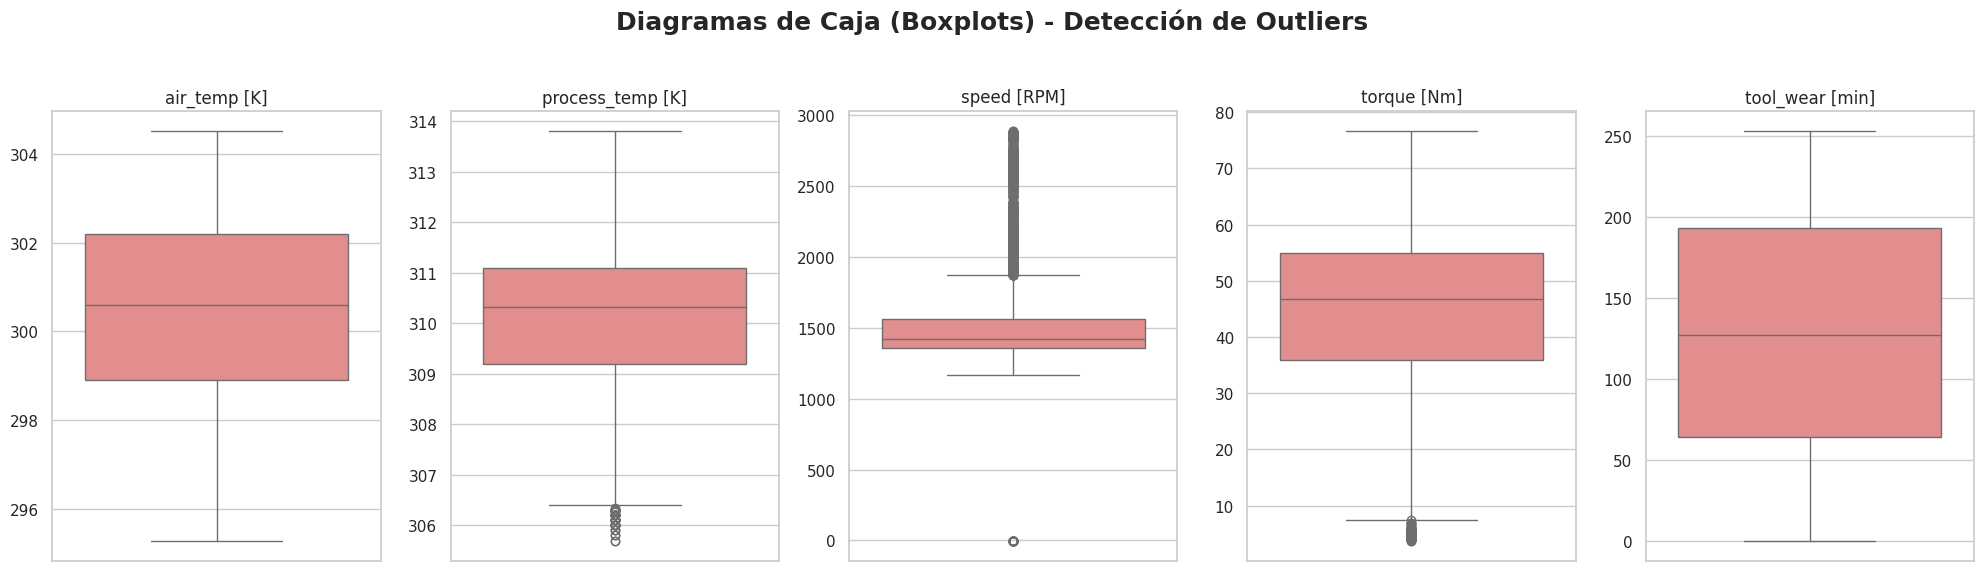

In [ ]:
# Configuración de estilo
sns.set_theme(style="whitegrid")
cols_num = ['air_temp [K]', 'process_temp [K]', 'speed [RPM]', 'torque [Nm]', 'tool_wear [min]']

# 1. GENERACIÓN DE BOXPLOTS (Para detectar valores atípicos)
fig1, axes1 = plt.subplots(nrows=1, ncols=5, figsize=(20, 6))
fig1.suptitle('Diagramas de Caja (Boxplots) - Detección de Outliers', fontsize=18, fontweight='bold')

for i, col in enumerate(cols_num):
    sns.boxplot(y=df[col], ax=axes1[i], color='lightcoral')
    axes1[i].set_title(col, fontsize=12)
    axes1[i].set_ylabel('')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

A continuación desarrollamos el código para generar los gráficos de Densidad de probabilidad, que nos permite ver la forma de la distribución sin la distracción de las barras del histograma.

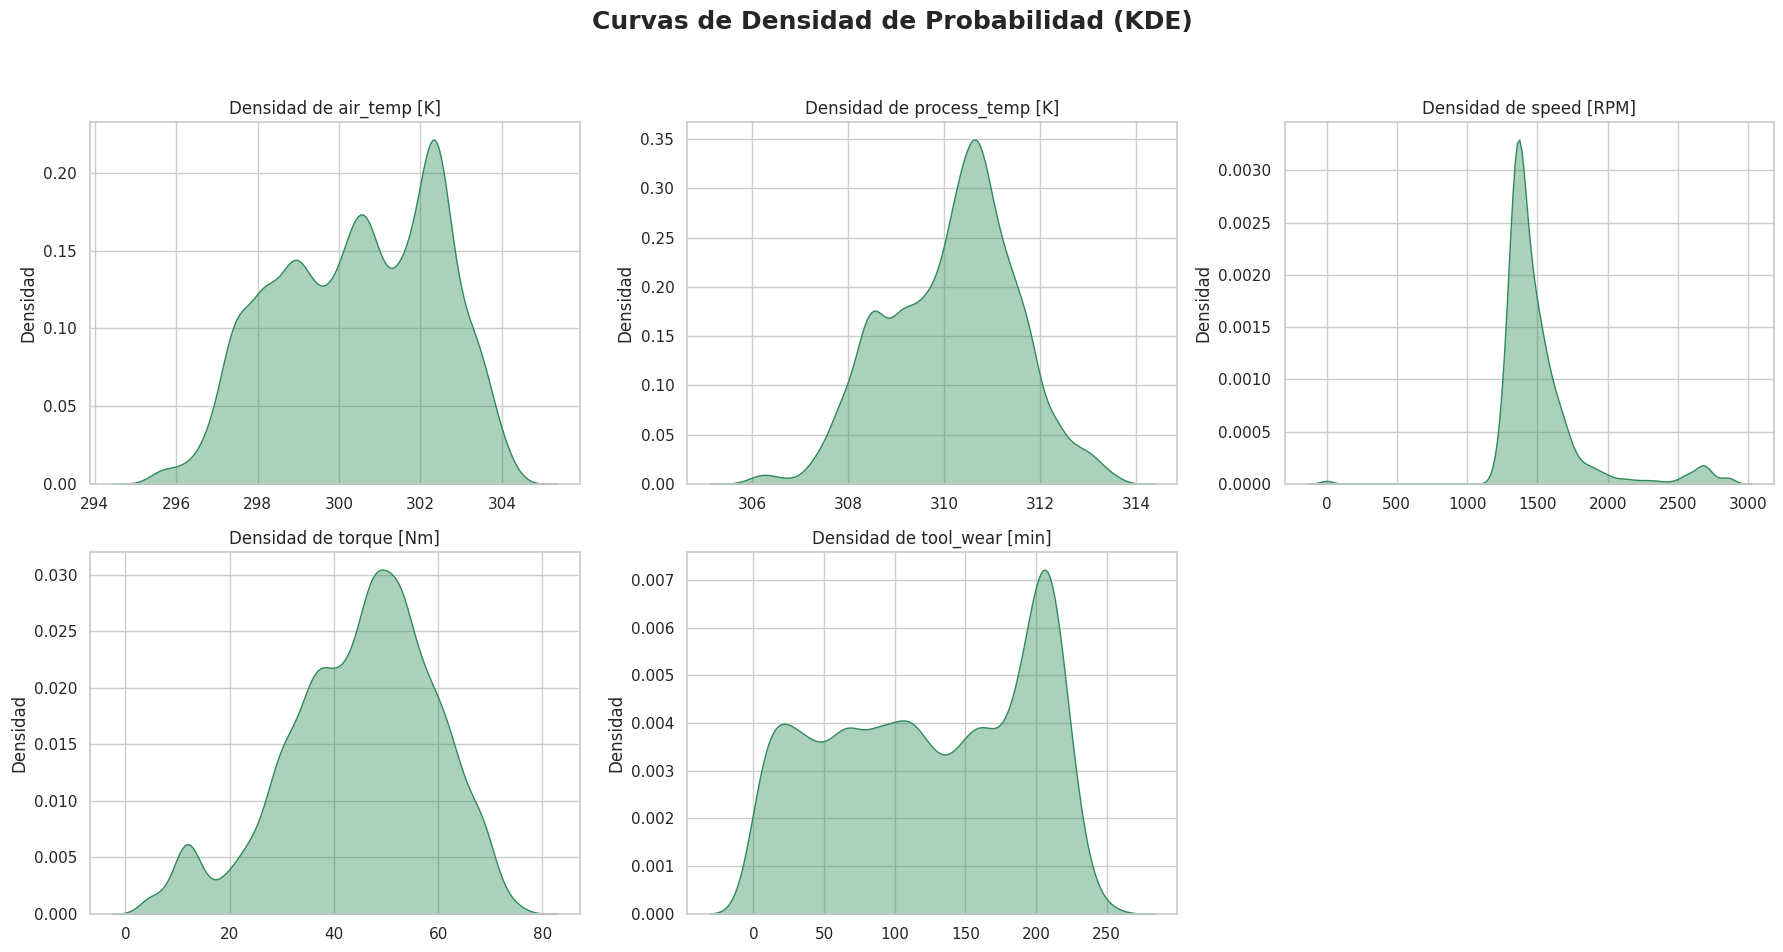

In [ ]:
# 2. GENERACIÓN DE GRÁFICOS DE DENSIDAD (KDE - Para ver la forma de los datos)
fig2, axes2 = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig2.suptitle('Curvas de Densidad de Probabilidad (KDE)', fontsize=18, fontweight='bold')

axes2 = axes2.flatten()

for i, col in enumerate(cols_num):
    sns.kdeplot(data=df[col], fill=True, ax=axes2[i], color='seagreen', alpha=0.4)
    axes2[i].set_title(f'Densidad de {col}', fontsize=12)
    axes2[i].set_xlabel('')
    axes2[i].set_ylabel('Densidad')

# Eliminamos el último espacio vacío
if len(cols_num) < len(axes2):
    fig2.delaxes(axes2[-1])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Proporciones
* **Gráfico de Torta (Pie Chart):** Es el estándar para mostrar "proporciones respecto al todo". Permite ver rápidamente qué porcentaje del dataset corresponde a cada categoría.
* **Gráfico de Barras (Countplot):** Es necesario para ver las frecuencias absolutas.
* **Justificación:** El análisis de proporciones del `target` es el paso más crítico antes del modelado. Nos permite identificar si el dataset está **desbalanceado**.

#### ¿Qué buscaremos en los resultados?

* **Product Type:** Ver si las máquinas trabajan más con productos tipo L, M o H. Esto influye porque el desgaste suele ser distinto según la calidad.
* **Target:** Este es el gráfico más importante de todo el análisis exploratorio. Veremos el **ratio de falla**. En mantenimiento predictivo, lo normal es que las fallas sean una minoría extrema.

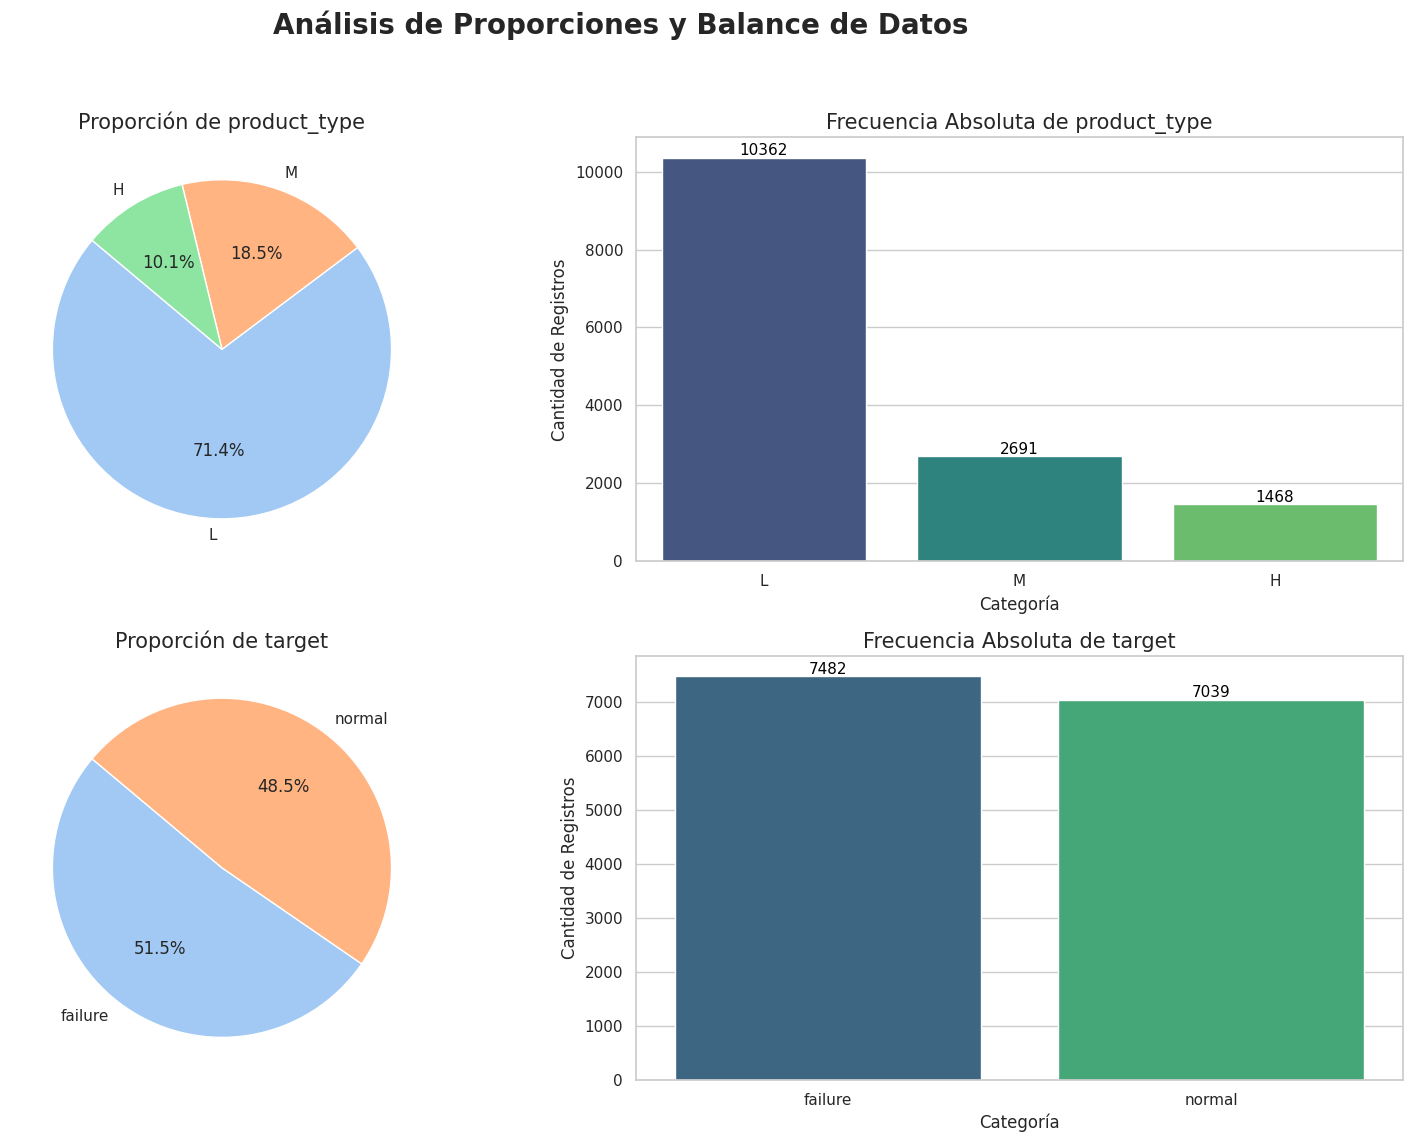

In [ ]:
# Configuración de estilo de la cátedra
sns.set_theme(style="whitegrid")

# Definimos las variables categóricas a analizar
cols_cat = ['product_type', 'target']

# Creamos una figura con 2 filas (una por variable) y 2 columnas (Pie y Bar)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12))
fig.suptitle('Análisis de Proporciones y Balance de Datos', fontsize=20, fontweight='bold')

for i, col in enumerate(cols_cat):
    # 1. Cálculo de frecuencias
    counts = df[col].value_counts()

    # 2. Gráfico de Torta (Proporciones porcentuales)
    axes[i, 0].pie(counts, labels=counts.index, autopct='%1.1f%%',
                   startangle=140, colors=sns.color_palette('pastel'))
    axes[i, 0].set_title(f'Proporción de {col}', fontsize=15)

    # 3. Gráfico de Barras (Frecuencias absolutas)
    # Corrección para evitar el FutureWarning: agregamos hue=counts.index y legend=False
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i, 1],
                hue=counts.index, palette='viridis', legend=False)

    axes[i, 1].set_title(f'Frecuencia Absoluta de {col}', fontsize=15)
    axes[i, 1].set_xlabel('Categoría')
    axes[i, 1].set_ylabel('Cantidad de Registros')

    # Agregamos etiquetas de valor sobre las barras
    for p in axes[i, 1].patches:
        axes[i, 1].annotate(f'{int(p.get_height())}',
                            (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='center', fontsize=11,
                            color='black', xytext=(0, 5),
                            textcoords='offset points')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

### Relación entre variables
En esta sección realizamos un análisis exhaustivo para identificar patrones de interacción entre las variables físicas del proceso y su grado de asociación con la ocurrencia de fallas. Buscamos detectar colinealidades (variables que dicen lo mismo) y descubrir qué sensores son los indicadores primarios de una anomalía en la máquina.

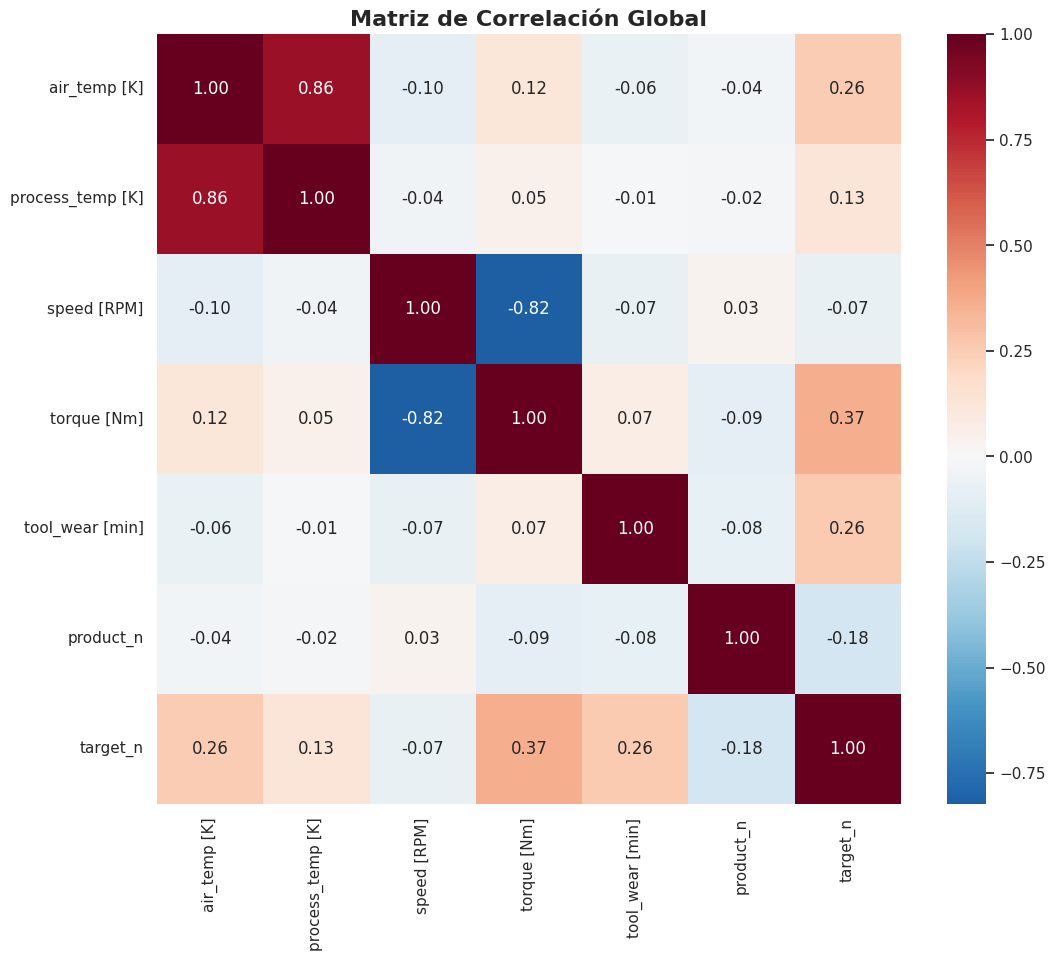

In [ ]:
# 1. Preparación: Creamos las columnas numéricas en df_analisis
df_analisis = df.copy()
df_analisis['target_n'] = df_analisis['target'].map({'normal': 0, 'failure': 1})
df_analisis['product_n'] = df_analisis['product_type'].map({'L': 0, 'M': 1, 'H': 2})

# Seleccionamos las columnas para la matriz (incluyendo las numéricas y el target original para el color)
cols_numericas = ['air_temp [K]', 'process_temp [K]', 'speed [RPM]',
                  'torque [Nm]', 'tool_wear [min]', 'product_n', 'target_n']

# 2. MATRIZ DE CORRELACIÓN (Heatmap)
plt.figure(figsize=(12, 10))
matriz_corr = df_analisis[cols_numericas].corr()
sns.heatmap(matriz_corr, annot=True, cmap='RdBu_r', center=0, fmt=".2f")
plt.title('Matriz de Correlación Global', fontsize=16, fontweight='bold')
plt.show()

**Matriz de dispersión**

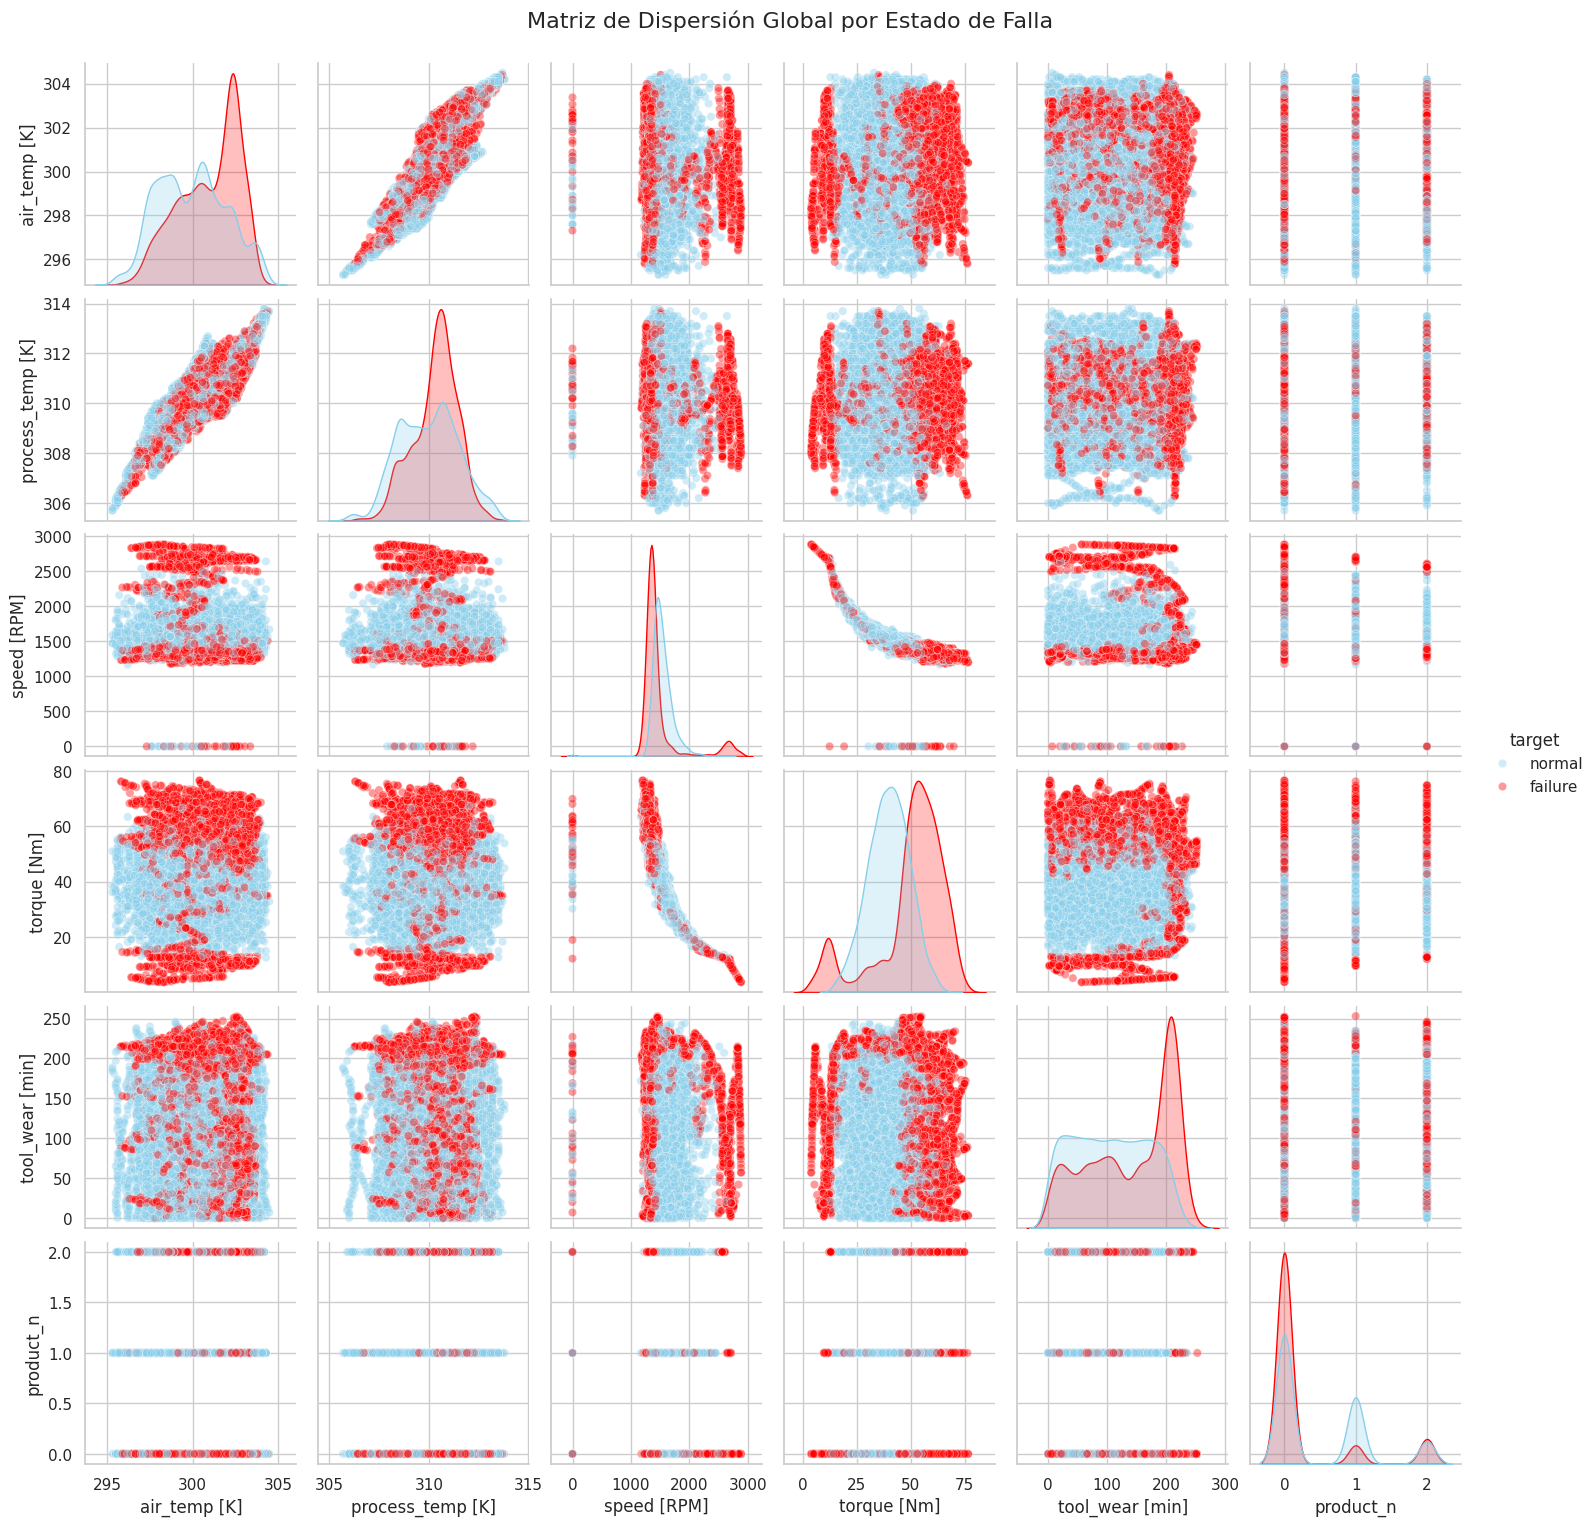

In [ ]:
# 3. MATRIZ DE DISPERSIÓN (Pairplot)
# Definimos las columnas que queremos ver en el gráfico de dispersión
# Usamos df_analisis porque ya tiene 'product_n' y 'target'
cols_plot = ['air_temp [K]', 'process_temp [K]', 'speed [RPM]',
             'torque [Nm]', 'tool_wear [min]', 'product_n', 'target']

sns.pairplot(df_analisis[cols_plot], hue='target',
             palette={'normal': 'skyblue', 'failure': 'red'},
             plot_kws={'alpha': 0.4})

plt.suptitle('Matriz de Dispersión Global por Estado de Falla', y=1.02, fontsize=16)
plt.show()

#### Análisis bivariado de relaciones críticas

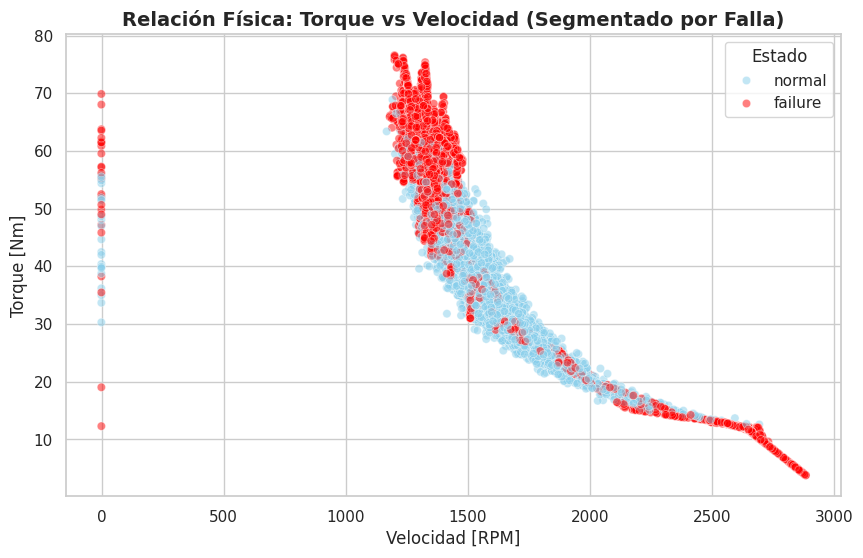

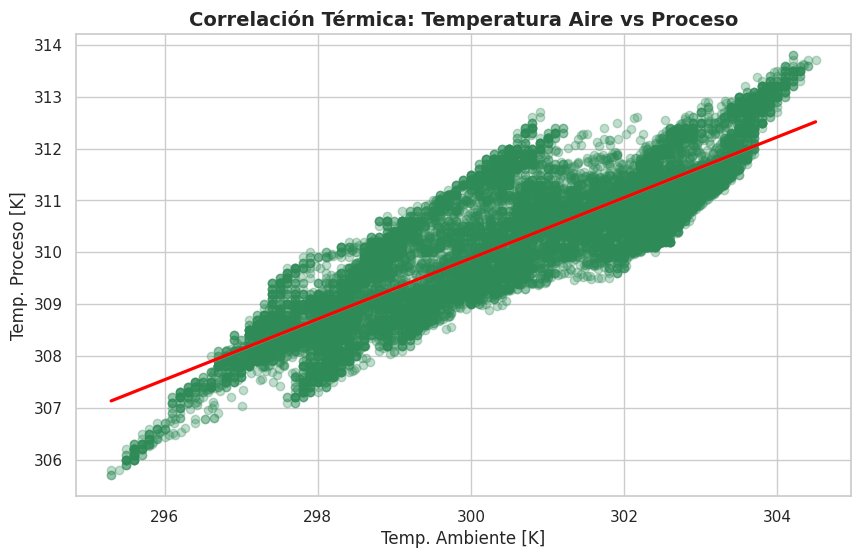

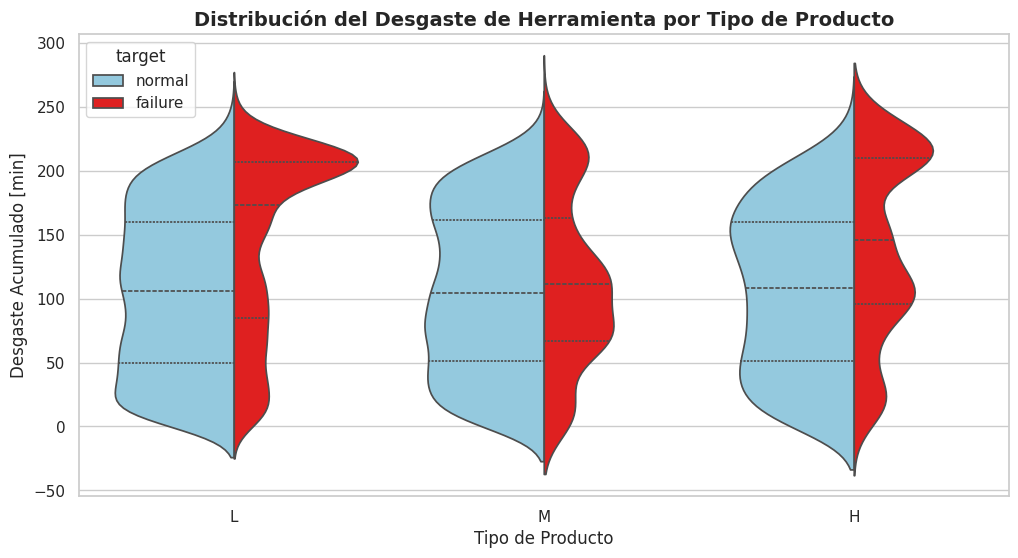

In [ ]:
# Configuración estética global
sns.set_theme(style="whitegrid")

# 1. RELACIÓN FÍSICA CRÍTICA: Torque vs Velocidad
# Justificación: Muestra la ley de potencia y cómo las fallas se agrupan en los extremos operativos.
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='speed [RPM]', y='torque [Nm]', hue='target',
                palette={'normal': 'skyblue', 'failure': 'red'}, alpha=0.5)
plt.title('Relación Física: Torque vs Velocidad (Segmentado por Falla)', fontsize=14, fontweight='bold')
plt.xlabel('Velocidad [RPM]')
plt.ylabel('Torque [Nm]')
plt.legend(title='Estado')
plt.show()

# 3. REDUNDANCIA TÉRMICA: Temperatura del Aire vs Proceso
# Justificación: Demuestra la colinealidad (0.88) y sugiere que lo importante es el diferencial térmico.
plt.figure(figsize=(10, 6))
sns.regplot(data=df, x='air_temp [K]', y='process_temp [K]',
            scatter_kws={'alpha':0.3, 'color':'seagreen'}, line_kws={'color':'red'})
plt.title('Correlación Térmica: Temperatura Aire vs Proceso', fontsize=14, fontweight='bold')
plt.xlabel('Temp. Ambiente [K]')
plt.ylabel('Temp. Proceso [K]')
plt.show()

# 4. EXIGENCIA DEL PROCESO: Desgaste por Tipo de Producto
# Justificación: Analiza si el tipo de producto (H, M, L) influye en cuándo ocurre la falla por desgaste.
plt.figure(figsize=(12, 6))
sns.violinplot(data=df, x='product_type', y='tool_wear [min]', hue='target',
               split=True, palette={'normal': 'skyblue', 'failure': 'red'}, inner="quart")
plt.title('Distribución del Desgaste de Herramienta por Tipo de Producto', fontsize=14, fontweight='bold')
plt.xlabel('Tipo de Producto')
plt.ylabel('Desgaste Acumulado [min]')
plt.show()

## Parte 2
### Procesamiento de datos
1) Preprocesamiento del conjunto de datos para que pueda utilizarse en modelos de aprendizaje automático teniendo en cuenta:
- Análisis de las variables.
- Valores erróneos/faltantes.
- Valores atípicos.
- Correlación entre variables.
- Procesamiento de variables categóricas.
- Balance del conjunto de datos.
- Normalización del conjunto de datos.

In [ ]:
# Importación de librerías específicas para preprocesamiento y modelado
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 1. ANÁLISIS Y SELECCIÓN DE VARIABLES
# Justificación: Las columnas 'idx' y 'parent_device_id' son identificadores únicos que no aportan
# información predictiva al modelo. Mantenerlas podría generar ruido o sobreajuste (overfitting).
df_proc = df.drop(['idx', 'parent_device_id'], axis=1)

In [ ]:
# 2. TRATAMIENTO DE VALORES ERRÓNEOS Y FALTANTES
# Identificación de faltantes
print("Valores faltantes por columna:\n", df_proc.isnull().sum())

# Justificación: 'air_temp [K]' presenta valores nulos. Utilizaremos
# la media para imputar estos valores ya que la distribución es aproximadamente normal.
imputer_mean = SimpleImputer(strategy='mean')
df_proc['air_temp [K]'] = imputer_mean.fit_transform(df_proc[['air_temp [K]']])

# Tratamiento de valores erróneos: 'speed [RPM]' tiene valores de -1 (imposible físicamente).
# Justificación: Reemplazamos los valores negativos por la mediana, que es una medida
# robusta frente a errores de carga, evitando sesgar la media.
median_speed = df_proc[df_proc['speed [RPM]'] > 0]['speed [RPM]'].median()
df_proc['speed [RPM]'] = df_proc['speed [RPM]'].apply(lambda x: median_speed if x <= 0 else x)

Valores faltantes por columna:
 product_type         0
air_temp [K]        40
process_temp [K]     0
speed [RPM]          0
torque [Nm]          0
tool_wear [min]      0
target               0
dtype: int64


In [ ]:
# 3. PROCESAMIENTO DE VARIABLES CATEGÓRICAS
# Justificación: Los modelos de ML requieren entradas numéricas.
# Para 'target' (binaria), aplicamos un mapeo directo (Label Encoding manual).
# Para 'product_type' (nominal), usamos One-Hot Encoding para evitar
# jerarquías artificiales entre las categorías L, M y H.

# Mapeo de la variable objetivo
df_proc['target'] = df_proc['target'].map({'normal': 0, 'failure': 1})

# One-Hot Encoding para product_type
encoder = OneHotEncoder(sparse_output=False, drop='first') # drop='first' para evitar la trampa de variables dummy
encoded_cols = encoder.fit_transform(df_proc[['product_type']])
df_encoded = pd.DataFrame(encoded_cols, columns=encoder.get_feature_names_out(['product_type']), index=df_proc.index)

# Unir y eliminar la original
df_proc = pd.concat([df_proc, df_encoded], axis=1).drop('product_type', axis=1)

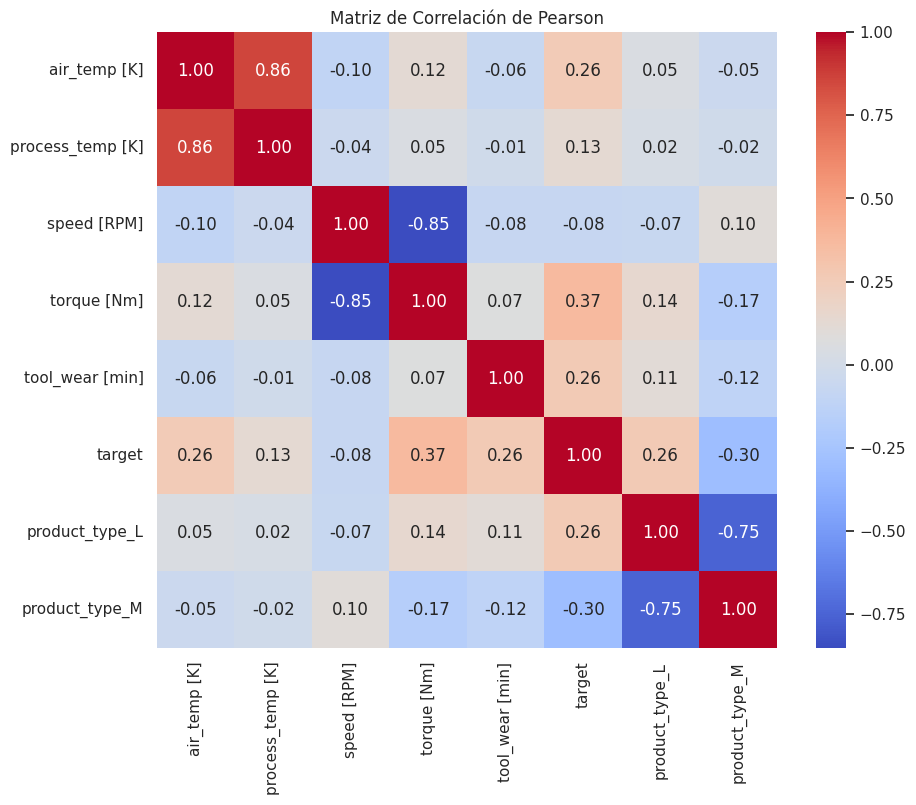

In [ ]:
# 4. CORRELACIÓN ENTRE VARIABLES
# Justificación: Analizamos la correlación de Pearson para detectar
# multicolinealidad. Si dos variables están altamente correlacionadas (p.ej. temperaturas),
# una podría ser redundante.
plt.figure(figsize=(10, 8))
sns.heatmap(df_proc.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación de Pearson')
plt.show()

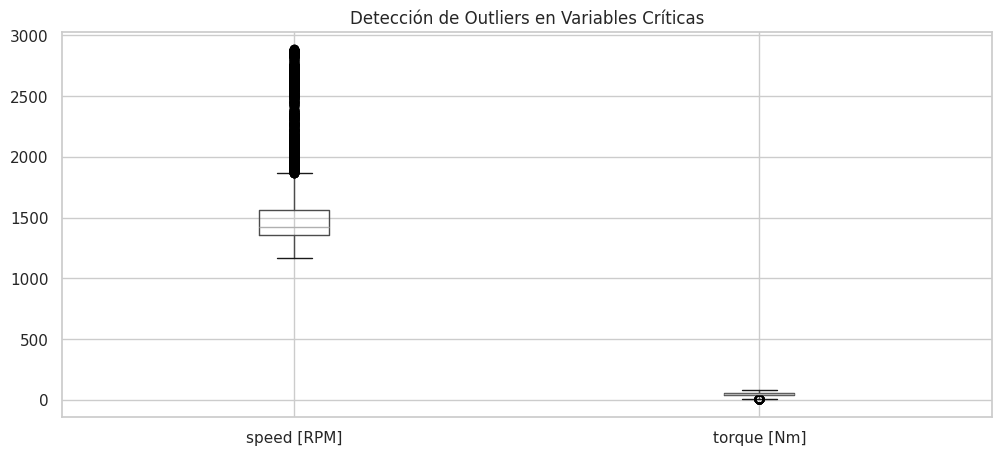

In [ ]:
# 5. VALORES ATÍPICOS (OUTLIERS)
# Justificación: Visualizamos mediante boxplots. Aunque existen outliers en 'speed' y 'torque',
# en mantenimiento predictivo estos valores suelen ser indicadores críticos de falla,
# por lo que decidimos mantenerlos para no perder capacidad de detección.
plt.figure(figsize=(12, 5))
df_proc[['speed [RPM]', 'torque [Nm]']].boxplot()
plt.title('Detección de Outliers en Variables Críticas')
plt.show()

In [ ]:
# 6. NORMALIZACIÓN DEL CONJUNTO DE DATOS
# Justificación: Dado que el análisis exploratorio mostró una gran cantidad de outliers en
# 'speed' y 'torque' (vistos en el boxplot), y entendiendo que estos puntos representan
# estados críticos de la máquina (señal de falla), optamos por RobustScaler.
# A diferencia de StandardScaler, este método utiliza la mediana y los cuartiles,
# asegurando que los outliers no distorsionen la escala de las demás variables.

scaler_robust = RobustScaler()
features_to_scale = ['air_temp [K]', 'process_temp [K]', 'speed [RPM]', 'torque [Nm]', 'tool_wear [min]']
df_proc[features_to_scale] = scaler_robust.fit_transform(df_proc[features_to_scale])

print("Escalado robusto finalizado. Los outliers se mantienen como señal pero no distorsionan la escala.")

Escalado robusto finalizado. Los outliers se mantienen como señal pero no distorsionan la escala.


In [ ]:
# 7. BALANCE DEL CONJUNTO DE DATOS
# Justificación: Como se vio en el Tema 8-A, las fallas industriales son eventos raros.
# Verificamos la proporción para decidir si aplicar técnicas de submuestreo o sobremuestreo.
proporcion = df_proc['target'].value_counts(normalize=True)
print("\nProporción de clases:\n", proporcion)

# (Opcional: Si los profesores piden aplicar el balanceo ahora)
# Debido al gran desbalance (típicamente <5% fallas), se recomienda usar RandomOverSampler o SMOTE
# en la etapa de entrenamiento para evitar que el modelo ignore la clase minoritaria.


Proporción de clases:
 target
1    0.515254
0    0.484746
Name: proportion, dtype: float64


**Conclusión**: El conjunto de datos está practicamente balanceado. Esto simplifica significativamente nuestro trabajo.

In [ ]:
# Exportar el dataset procesado a un archivo CSV para Inteligencia Artificial
# index=False evita que se guarde la columna de índices de Pandas como una columna extra
df_proc.to_csv('mantenimiento_procesado.csv', index=False)

print("¡Archivo exportado correctamente!")

### Entrenamiento de modelos
Entrenamiento y resultados obtenidos con al menos dos modelos vistos en el curso, teniendo en cuenta:
- División del conjunto de datos para entrenamiento y prueba.
- Búsqueda de hiperparámetros para mejorar el rendimiento de los modelos.
- Evaluación del modelo con las métricas convenientes.

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay


## Usando Regresión Logística y K-Nearest Neighbors

In [ ]:
# 1. DIVISIÓN DEL CONJUNTO DE DATOS
# Justificación: Siguiendo la Clase 5, dividimos en 75% entrenamiento y 25% prueba.
# Usamos random_state para asegurar la reproducibilidad de los resultados.
X = df_proc.drop('target', axis=1)
y = df_proc['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print(f"Dimensiones de Entrenamiento: {X_train.shape}")
print(f"Dimensiones de Prueba: {X_test.shape}")

Dimensiones de Entrenamiento: (10890, 7)
Dimensiones de Prueba: (3631, 7)


In [ ]:
# ---------------------------------------------------------
# 2. MODELO 1: REGRESIÓN LOGÍSTICA
# ---------------------------------------------------------
print("\n--- Entrenando Regresión Logística ---")

# Búsqueda de hiperparámetros (C: intensidad de la regularización)
param_grid_lr = {'C': [0.01, 0.1, 1, 10, 100]}
grid_lr = GridSearchCV(LogisticRegression(max_iter=1000), param_grid_lr, cv=5)
grid_lr.fit(X_train, y_train)

best_lr = grid_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test)

print(f"Mejor parámetro C: {grid_lr.best_params_}")


--- Entrenando Regresión Logística ---
Mejor parámetro C: {'C': 0.1}


In [ ]:
# ---------------------------------------------------------
# 3. MODELO 2: K-NEAREST NEIGHBORS (k-NN)
# ---------------------------------------------------------
print("\n--- Entrenando k-NN ---")

# Búsqueda de hiperparámetros (n_neighbors: cantidad de vecinos)
param_grid_knn = {'n_neighbors': [3, 5, 7, 9, 11]}
grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5)
grid_knn.fit(X_train, y_train)

best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)

print(f"Mejor n_neighbors: {grid_knn.best_params_}")


--- Entrenando k-NN ---
Mejor n_neighbors: {'n_neighbors': 3}



Resultados para Regresión Logística:
              precision    recall  f1-score   support

           0       0.84      0.81      0.83      1760
           1       0.83      0.86      0.84      1871

    accuracy                           0.84      3631
   macro avg       0.84      0.83      0.83      3631
weighted avg       0.84      0.84      0.84      3631



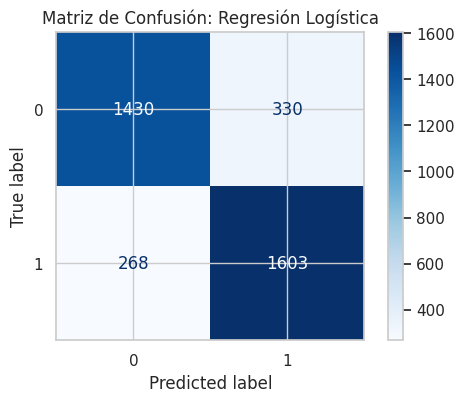


Resultados para k-NN:
              precision    recall  f1-score   support

           0       0.98      0.91      0.94      1760
           1       0.92      0.98      0.95      1871

    accuracy                           0.95      3631
   macro avg       0.95      0.95      0.95      3631
weighted avg       0.95      0.95      0.95      3631



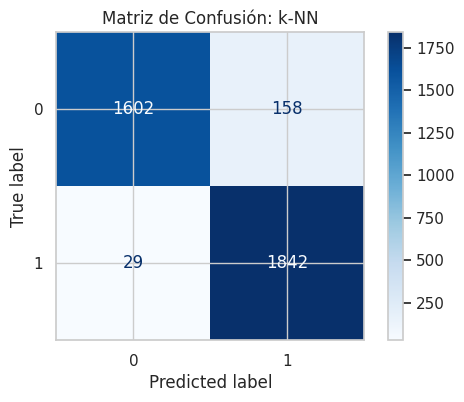

In [ ]:
# ---------------------------------------------------------
# 4. EVALUACIÓN Y COMPARACIÓN DE RESULTADOS
# ---------------------------------------------------------

def evaluar_modelo(y_true, y_pred, nombre_modelo):
    print(f"\nResultados para {nombre_modelo}:")
    print(classification_report(y_true, y_pred))

    # Matriz de Confusión
    fig, ax = plt.subplots(figsize=(6, 4))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, ax=ax, cmap='Blues')
    plt.title(f'Matriz de Confusión: {nombre_modelo}')
    plt.show()

evaluar_modelo(y_test, y_pred_lr, "Regresión Logística")
evaluar_modelo(y_test, y_pred_knn, "k-NN")

## Usando Boosting


--- Entrenando Boosting (GradientBoostingClassifier) ---
Fitting 3 folds for each of 27 candidates, totalling 81 fits
Mejores hiperparámetros para Gradient Boosting: {'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200}

Resultados para Boosting (GradientBoostingClassifier):
              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1760
           1       0.97      0.99      0.98      1871

    accuracy                           0.98      3631
   macro avg       0.98      0.98      0.98      3631
weighted avg       0.98      0.98      0.98      3631



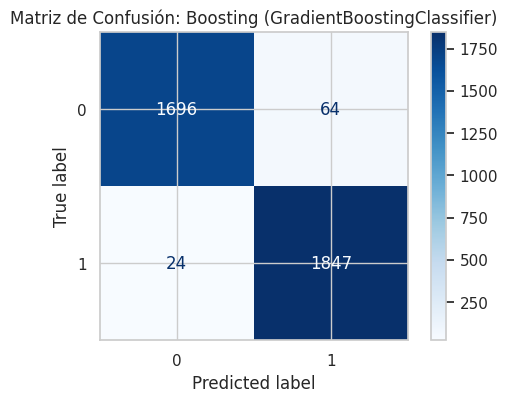

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

print("\n--- Entrenando Boosting (GradientBoostingClassifier) ---")

# Búsqueda de hiperparámetros
param_grid_gb = {
    'n_estimators': [50, 100, 200], # Número de etapas de boosting
    'learning_rate': [0.01, 0.1, 0.2], # Contribución de cada árbol
    'max_depth': [3, 5, 7] # Profundidad máxima de los estimadores individuales
}

grid_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid_gb, cv=3, n_jobs=-1, verbose=1)
grid_gb.fit(X_train, y_train)

best_gb = grid_gb.best_estimator_
y_pred_gb = best_gb.predict(X_test)

print(f"Mejores hiperparámetros para Gradient Boosting: {grid_gb.best_params_}")

# Evaluación del modelo
evaluar_modelo(y_test, y_pred_gb, "Boosting (GradientBoostingClassifier)")
